# E0：Euclidean 表达表示实验

普通 AE 欧氏表示；可切换 PCA，检验基础潜在表示能否区分稀有细胞。

本 notebook 独立使用一张 GPU。请选用独立 kernel，从第一格顺序运行。默认留出 1/2/3，每折 5 seeds、100 epochs；三组同时运行时使用相同配置。

当前只做表示验证，输出冻结编码器与评价；后续才将得到验证的表示接入 DeepSpatial UOT。详细指标与实验边界见 [README](README.md)。

In [1]:
# 必须在导入 torch 前运行；换卡时重启本 notebook 的 kernel。
import os
import sys
GPU_ID = "7"  # 物理 GPU 编号；调度器已限制可见卡时可设 None，保留分配。
if "torch" in sys.modules:
    raise RuntimeError("当前 kernel 已导入 torch，请重启 kernel 后从第一格运行。")
if GPU_ID is not None:
    os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES", "scheduler/default"))


CUDA_VISIBLE_DEVICES = 7


In [2]:
from pathlib import Path
from copy import deepcopy
# 支持从仓库根目录、MMDeepSpatial 或其子目录启动；也支持仅上传 MMDeepSpatial。
PROJECT = next((candidate for parent in (Path.cwd(), *Path.cwd().parents)
                for candidate in (parent, parent / "MMDeepSpatial")
                if (candidate / "mmdeepspatial/experiment.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("请在 MMDeepSpatial 或其父目录打开 notebook。")
sys.path.insert(0, str(PROJECT))
from mmdeepspatial.experiment import DEFAULT_CONFIG, run_experiment
from mmdeepspatial.data import input_paths
import pandas as pd
print("MMDeepSpatial:", PROJECT)


MMDeepSpatial: /3250608056/code/DeepSpatial/MMDeepSpatial


## 统一配置

三组的划分、种子、维度、训练和 probe 参数必须保持一致。`log1p` 适用于非负未 log 表达；已 log 或 scaled 的数据统一改 `identity`。首次检查可三组同时改成 holdout `[2]`、seed `[0]`、epochs `2`，正式运行使用全新输出目录。

In [3]:
ARM = "E0"
DATA_GLOB = str(PROJECT.parent / "data/merfish_mouse_hypothalamus/**/merfish_[0-4].h5ad")
OUTPUT_ROOT = PROJECT / "outputs/representations_v2"
HOLDOUTS = [1, 2, 3]  # 文件自然排序后的零起始编号，必须为中间切片
SEEDS = [42, 0, 1, 2, 3]
EPOCHS = 100
MAX_TANGENT_RADIUS = 1.5  # sqrt(c) * tangent norm 的平滑上限
DIAGNOSTIC_ALPHAS = [0.25, 0.75]  # 仅作诊断，不在测试切片选择最优值
DIM = 32  # E0=32E；E1=32H；E2=16E+16H；AE 参数量相同
LABEL_KEY = "cell_class"
LAYER = None  # 例如 "counts"；None 读取 X
TRANSFORM = "log1p"  # 已经 log / 标准化的 X 改成 "identity"
E0_METHOD = "ae"  # E0 可另跑 "pca"；E1/E2 忽略此值
DEVICE = "cuda"  # 本 kernel 可见的单卡；CPU 冒烟测试用 "cpu"

CONFIG = deepcopy(DEFAULT_CONFIG)
CONFIG.update(input_glob=DATA_GLOB, output_root=str(OUTPUT_ROOT), holdouts=HOLDOUTS,
              seeds=SEEDS, epochs=EPOCHS, dim=DIM, label_key=LABEL_KEY, layer=LAYER,
              transform=TRANSFORM, e0_method=E0_METHOD, device=DEVICE,
              max_tangent_radius=MAX_TANGENT_RADIUS, diagnostics=True,
              diagnostic_alphas=DIAGNOSTIC_ALPHAS)
# 其他固定参数均来自 DEFAULT_CONFIG；改动时三个 notebook 同步修改。
# 例如 CONFIG.update(batch_size=512, curvature=1.0, fusion_alpha=0.5)
CONFIG


{'input_glob': '/3250608056/code/DeepSpatial/data/merfish_mouse_hypothalamus/**/merfish_[0-4].h5ad',
 'output_root': '/3250608056/code/DeepSpatial/MMDeepSpatial/outputs/representations_v2',
 'holdouts': [1, 2, 3],
 'seeds': [42, 0, 1, 2, 3],
 'label_key': 'cell_class',
 'layer': None,
 'transform': 'log1p',
 'n_genes': 0,
 'rare_fraction': 0.05,
 'dim': 32,
 'hidden': 128,
 'epochs': 100,
 'batch_size': 512,
 'lr': 0.001,
 'weight_decay': 1e-05,
 'grad_clip': 5.0,
 'curvature': 1.0,
 'fusion_alpha': 0.5,
 'log_every': 10,
 'e0_method': 'ae',
 'device': 'cuda',
 'cpu_threads': 4,
 'retrieval_ks': [1, 5, 15],
 'query_chunk': 128,
 'reference_chunk': 2048,
 'coverage_quantile': 0.95,
 'coverage_calibration_max': 2048,
 'probe_c': 1.0,
 'probe_class_weight': 'balanced',
 'probe_max_iter': 2000,
 'shuffled_probe': False,
 'max_tangent_radius': 1.5,
 'diagnostics': True,
 'diagnostic_alphas': [0.25, 0.75]}

In [4]:
paths = input_paths(CONFIG["input_glob"])
display(pd.DataFrame({"slice_index": range(len(paths)), "file": [str(p) for p in paths],
                      "used_as_holdout": [i in HOLDOUTS for i in range(len(paths))]}))
print("总训练任务:", len(HOLDOUTS) * len(SEEDS))
print("数据预处理、编码器和 probe 均在隐藏切片评价前冻结。")


,slice_index,file,used_as_holdout
0,0,/3250608056/code/DeepSpatial/data/merfish_mous...,False
1,1,/3250608056/code/DeepSpatial/data/merfish_mous...,True
2,2,/3250608056/code/DeepSpatial/data/merfish_mous...,True
3,3,/3250608056/code/DeepSpatial/data/merfish_mous...,True
4,4,/3250608056/code/DeepSpatial/data/merfish_mous...,False


总训练任务: 15
数据预处理、编码器和 probe 均在隐藏切片评价前冻结。


## 训练与评价

每组运行 3 个留出切片 × 5 个 seed，共 15 次编码器训练。输出到新的 `representations_v2`，保留上一轮结果。

双曲映射先做平滑径向压缩；训练记录原始切空间范数、球半径分布和接近平滑上限的比例。E0 加 L2/余弦诊断，E1 加角度诊断，E2 加分支独立 probe 与固定权重诊断。所有 probe 与距离标定都在读取测试切片前完成。

这些仍是探索性表示实验；本轮调参已参考上一轮相同切片，最终结论需要独立样本验证。


In [5]:
results = run_experiment(ARM, CONFIG)
display(results[["arm", "holdout", "seed", "rare_macro_auprc", "rare_macro_f1",
                 "rare_macro_retrieval_hit_at_5", "rare_macro_knn_purity_at_5",
                 "common_macro_f1", "overall_accuracy", "trainable_parameters"]])


E0 | cuda | 5 slices | output=/3250608056/code/DeepSpatial/MMDeepSpatial/outputs/representations_v2/E0_ae
Start E0 holdout=1 seed=42 train=(22760, 155)
E0 seed=42 epoch=1/100 mse=0.86958 boundary=0.000%
E0 seed=42 epoch=10/100 mse=0.49067 boundary=0.000%
E0 seed=42 epoch=20/100 mse=0.45122 boundary=0.000%
E0 seed=42 epoch=30/100 mse=0.43125 boundary=0.000%
E0 seed=42 epoch=40/100 mse=0.41573 boundary=0.000%
E0 seed=42 epoch=50/100 mse=0.40540 boundary=0.000%
E0 seed=42 epoch=60/100 mse=0.39791 boundary=0.000%
E0 seed=42 epoch=70/100 mse=0.39210 boundary=0.000%
E0 seed=42 epoch=80/100 mse=0.38736 boundary=0.000%
E0 seed=42 epoch=90/100 mse=0.38293 boundary=0.000%
E0 seed=42 epoch=100/100 mse=0.37928 boundary=0.000%
 rare_macro_auprc  rare_macro_f1  overall_accuracy
         0.700684       0.631139          0.901925
Start E0 holdout=1 seed=0 train=(22760, 155)
E0 seed=0 epoch=1/100 mse=0.87986 boundary=0.000%
E0 seed=0 epoch=10/100 mse=0.48748 boundary=0.000%
E0 seed=0 epoch=20/100 mse=0

,arm,holdout,seed,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,common_macro_f1,overall_accuracy,trainable_parameters
0,E0,1,42,0.700684,0.631139,0.700377,0.541372,0.922246,0.901925,48315
1,E0,1,0,0.686604,0.608840,0.731679,0.561716,0.921013,0.899586,48315
2,E0,1,1,0.674343,0.623312,0.757543,0.564909,0.913832,0.886629,48315
3,E0,1,2,0.732420,0.649440,0.734777,0.546315,0.915014,0.897067,48315
4,E0,1,3,0.678349,0.627611,0.741499,0.567137,0.918636,0.893648,48315
5,E0,2,42,0.771321,0.600488,0.718445,0.561043,0.905185,0.874452,48315
6,E0,2,0,0.783237,0.632495,0.747680,0.589833,0.909742,0.881539,48315
7,E0,2,1,0.810298,0.629721,0.755852,0.589583,0.909228,0.884576,48315
8,E0,2,2,0.768182,0.608682,0.755829,0.596342,0.908222,0.881876,48315
9,E0,2,3,0.799476,0.623556,0.752943,0.578703,0.915212,0.894195,48315


,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,rare_macro_coverage,common_macro_f1
holdout,,,,,,
1,0.694480,0.628068,0.733175,0.556290,0.925257,0.918148
2,0.786503,0.618988,0.746150,0.583101,0.954837,0.909518
3,0.726029,0.636953,0.772066,0.609228,0.965872,0.922748


,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,rare_macro_coverage,common_macro_f1
mean,0.735671,0.628003,0.750464,0.582873,0.948655,0.916805
std,0.046763,0.008982,0.019801,0.026470,0.021001,0.006717


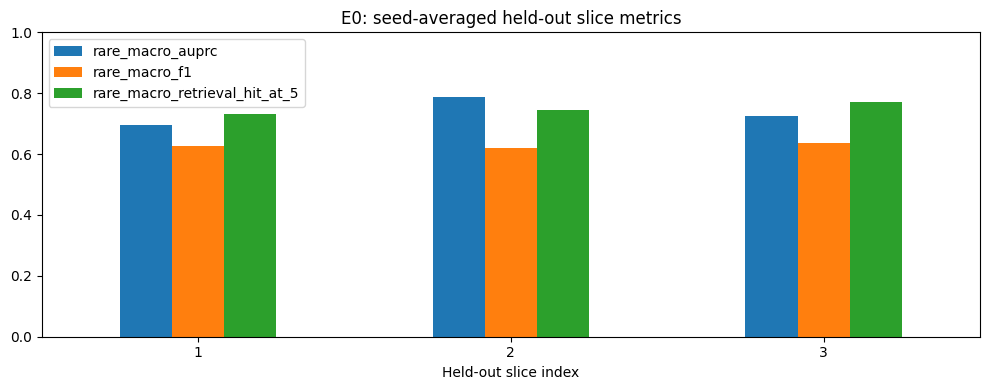

rare_macro_auprc  rare_macro_f1  \
variant       holdout                                    
l2_normalized 1                0.677125       0.625281   
              2                0.757563       0.616835   
              3                0.713191       0.627642   
main          1                0.694480       0.628068   
              2                0.786503       0.618988   
              3                0.726029       0.636953   

                       rare_macro_retrieval_hit_at_5  \
variant       holdout                                  
l2_normalized 1                             0.741988   
              2                             0.785023   
              3                             0.777879   
main          1                             0.733175   
              2                             0.746150   
              3                             0.772066   

                       rare_macro_knn_purity_at_5  rare_macro_coverage  \
variant       holdout                                                    
l2_normalized 1                          0.570360             0.924397   
              2                          0.591783             0.952711   
              3                          0.607486             0.959181   
main          1                          0.556290             0.925257   
              2                          0.583101             0.954837   
              3                          0.609228             0.965872   

                       common_macro_f1  
variant       holdout                   
l2_normalized 1               0.915664  
              2               0.910619  
              3               0.922626  
main          1               0.918148  
              2               0.909518  
              3               0.922748

In [6]:
# 描述性汇总：先在每折内平均 seeds，再展示折间统计。
# 同一组织的留出折有相关性，此标准差不代表独立动物重复的置信区间。
metrics = ["rare_macro_auprc", "rare_macro_f1", "rare_macro_retrieval_hit_at_5",
           "rare_macro_knn_purity_at_5", "rare_macro_coverage", "common_macro_f1"]
by_fold = results.groupby("holdout")[metrics].mean()
display(by_fold)
display(by_fold.agg(["mean", "std"]))
import matplotlib.pyplot as plt
axes = by_fold[["rare_macro_auprc", "rare_macro_f1", "rare_macro_retrieval_hit_at_5"]].plot.bar(
    figsize=(10, 4), ylim=(0, 1), rot=0, title=f"{ARM}: seed-averaged held-out slice metrics")
axes.set_xlabel("Held-out slice index")
plt.tight_layout()
plt.show()

# 冻结编码器诊断：按 variant 与切片汇总，保留全部 seed。
diagnostic_runs = pd.concat([pd.read_csv(
    OUTPUT_ROOT / f"{ARM}_{'pca' if ARM == 'E0' and E0_METHOD == 'pca' else 'ae'}"
    / f"holdout_{h}" / f"seed_{s}" / "diagnostics_summary.csv")
    for h in HOLDOUTS for s in SEEDS], ignore_index=True)
display(diagnostic_runs.groupby(["variant", "holdout"])[metrics].mean())
if ARM != "E0":
    display(results[["holdout", "seed", "test_near_boundary_fraction",
                     "test_ball_radius_fraction_median", "test_ball_radius_fraction_std",
                     "test_near_mapping_limit_fraction"]])


## 三组完成后的配对比较

等 E0/E1/E2 全部完成后，将下一格开关改为 True 再执行。比较器检查协议、输入、预处理、fold/seed 和 AE 参数量，输出 paired delta 与逐类型表。跨切片检索是类型一致性代理，不是真实细胞配对准确率。

In [8]:
COMPARE_WHEN_READY = True  # 需要所有折和种子完成后再运行；否则报错。
if COMPARE_WHEN_READY:
    from mmdeepspatial.compare import compare_runs
    all_runs, aggregate, all_types = compare_runs(OUTPUT_ROOT, e0_method=E0_METHOD)
    display(aggregate)
    display(all_types[all_types.is_rare].sort_values(["cell_type", "arm", "holdout", "seed"]))


,arm,method,rare_macro_auprc_mean,rare_macro_auprc_std,rare_macro_f1_mean,rare_macro_f1_std,rare_macro_recall_mean,rare_macro_recall_std,rare_macro_coverage_mean,rare_macro_coverage_std,...,common_macro_knn_purity_at_15_mean,common_macro_knn_purity_at_15_std,overall_accuracy_mean,overall_accuracy_std,train_seconds_mean,train_seconds_std,peak_train_gpu_mb_mean,peak_train_gpu_mb_std,test_reconstruction_mse_mean,test_reconstruction_mse_std
0,E0,ae,0.735671,0.046763,0.628003,0.008982,0.804679,0.055445,0.948655,0.021001,...,0.885533,0.008751,0.891718,0.007267,117.394753,59.822754,70.373242,0.042794,0.408359,0.010057
1,E1,ae,0.721448,0.028391,0.632379,0.017039,0.779483,0.032098,0.952340,0.018529,...,0.899615,0.005012,0.898508,0.008829,76.245865,14.175592,70.713086,0.042794,0.476606,0.014154
2,E2,ae,0.726787,0.044273,0.624669,0.010940,0.787733,0.041270,0.954149,0.022675,...,0.858614,0.004071,0.892500,0.007685,95.889937,9.578118,70.588086,0.042794,0.433934,0.012468


,cell_type,train_n,train_fraction,test_n,test_prevalence,predicted_n,is_rare,rarity,train_supported,test_present,...,retrieval_hit_at_15,knn_purity_at_15,coverage_threshold,calibration_n,coverage,coverage_status,arm,method,holdout,seed
17,Endothelial 2,103,0.004525,41,0.007378,70,True,ultra_rare,True,True,...,0.707317,0.250407,0.678906,103,0.95122,ok,E0,ae,1,0
32,Endothelial 2,103,0.004525,41,0.007378,70,True,ultra_rare,True,True,...,0.804878,0.252033,0.713237,103,0.95122,ok,E0,ae,1,1
47,Endothelial 2,103,0.004525,41,0.007378,59,True,ultra_rare,True,True,...,0.756098,0.250407,0.734577,103,0.97561,ok,E0,ae,1,2
62,Endothelial 2,103,0.004525,41,0.007378,65,True,ultra_rare,True,True,...,0.780488,0.292683,0.778884,103,1.00000,ok,E0,ae,1,3
2,Endothelial 2,103,0.004525,41,0.007378,69,True,ultra_rare,True,True,...,0.780488,0.256911,0.657807,103,0.95122,ok,E0,ae,1,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
629,Pericytes,152,0.006751,52,0.008961,55,True,ultra_rare,True,True,...,0.942308,0.806410,0.702161,152,1.00000,ok,E2,ae,3,0
644,Pericytes,152,0.006751,52,0.008961,59,True,ultra_rare,True,True,...,0.942308,0.830769,0.719699,152,1.00000,ok,E2,ae,3,1
659,Pericytes,152,0.006751,52,0.008961,61,True,ultra_rare,True,True,...,0.942308,0.825641,0.716438,152,1.00000,ok,E2,ae,3,2
674,Pericytes,152,0.006751,52,0.008961,56,True,ultra_rare,True,True,...,0.961538,0.821795,0.686668,152,1.00000,ok,E2,ae,3,3
